<div align="center">

#####

#Teoría de Circuitos 2

##Trabajo Práctico N°9

**Estudiante: Nahir Lewartowski**

</div>

---

#**1) Para la siguiente transferencia de tensiones:**


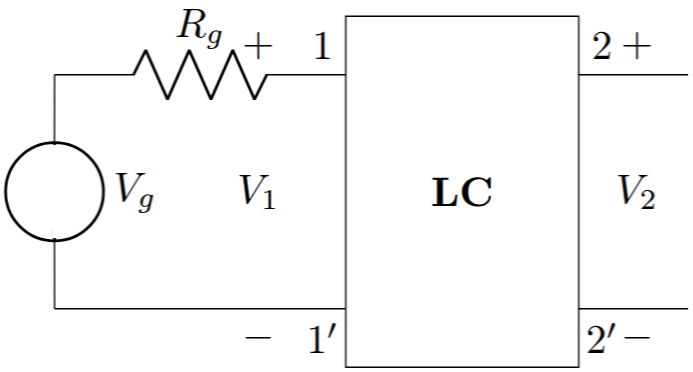

$$T(s)=\frac{V_{2}}{V_{g}}=\frac{k \cdot s \cdot (s^{2}+1/16)}{s^{3}+2s^{2}+2s+1}$$

##**Sintetizar considerando $R_g=1$, hallar el valor de k que cumple con la síntesis y el valor de los componentes hallados**

Dado que $R_{g} = 1$, separo el polinomio del denominador $Q(s) = s^{3}+2s^{2}+2s+1$ en su parte par $M(s)$ y su parte impar $N(s)$:   

$M(s) = 2s^{2} + 1$

$N(s) = s^{3} + 2s$


 Uso la admitancia de entrada $Y_{11} = \frac{1}{Z_{11}}$ para remover un inductor en derivación de forma parcial.

In [ ]:
import sympy as sp
from IPython.display import display, Math

s, k = sp.symbols('s k')

P = k * s * (s**2 + sp.Rational(1, 16))
Q = s**3 + 2*s**2 + 2*s + 1

M = 2*s**2 + 1
N = s**3 + 2*s

Z11 = N / M
Z21 = P / M

print("Parámetro Z11:\n")
display(Math('Z_{11} = ' + sp.latex(Z11)))

print("\nParámetro Z21:\n")
display(Math('Z_{21} = ' + sp.latex(Z21)))

ceros_transmision = sp.solve(P, s)
print("\nCeros de transmisión (frecuencias donde Z21 se anula):\n")
display(ceros_transmision)

Parámetro Z11:



<IPython.core.display.Math object>


Parámetro Z21:



<IPython.core.display.Math object>


Ceros de transmisión (frecuencias donde Z21 se anula):



[0, -I/4, I/4]

Extraigo solo una fracción de un inductor en derivación para forzar a que el resto del circuito tenga un cero exactamente en la frecuencia deseada $\omega = 1/4$.


In [ ]:
Y11 = 1 / Z11

w_z2 = -sp.Rational(1, 16)

k0 = sp.limit(s * Y11, s, 0)
print(f"Residuo máximo en s=0 (k0): {k0}\n")
print(f"Inductor máximo que se puede extraer en derivación: L_max = {1/k0} H\n")

L1_p = sp.symbols('L1_p')

sYA_eval = sp.cancel(s * Y11).subs(s**2, w_z2)
eq_L1 = sp.Eq(sYA_eval - 1/L1_p, 0)

L1_val = sp.solve(eq_L1, L1_p)[0]
print(f"Valor del inductor para remoción parcial: L1_p = {L1_val} H")

YA = sp.simplify(Y11 - 1/(L1_val * s))

print("\nAdmitancia remanente Y_A:\n")
display(Math('Y_A = ' + sp.latex(YA)))

num_YA = sp.fraction(sp.cancel(YA))[0]
print("\nRaíces del numerador de Y_A:")
display(sp.solve(num_YA, s))

Residuo máximo en s=0 (k0): 1/2

Inductor máximo que se puede extraer en derivación: L_max = 2 H

Valor del inductor para remoción parcial: L1_p = 31/14 H

Admitancia remanente Y_A:



<IPython.core.display.Math object>


Raíces del numerador de Y_A:


[-I/4, I/4]

La admitancia $Y_A$ tiene un cero en esa frecuencia, lo cual implica que la impedancia remanente $Z_A = \frac{1}{Y_A}$ posee un polo. Físicamente, un polo de impedancia en la rama de paso (serie) corresponde a un circuito tanque LC en paralelo.

In [ ]:
ZA = 1 / YA

kz = sp.cancel(ZA * (s**2 + sp.Rational(1, 16)) / s).subs(s**2, w_z2)
print(f"Residuo del tanque (kz): {kz}")

C2 = 1 / kz
L2 = 1 / (C2 * (-w_z2))
print(f"\nComponentes del tanque serie: C2 = {C2} F, L2 = {L2} H\n")

Z_tanque = (kz * s) / (s**2 + sp.Rational(1, 16))
ZB = sp.simplify(ZA - Z_tanque)
print("\nImpedancia remanente final Z_B:\n")
display(Math('Z_B = ' + sp.latex(ZB)))

L3 = sp.simplify(ZB / s)
print(f"\nInductor final: L3 = {L3} H\n")

Z21_sintetizado = sp.cancel(1 / ( (1/(s*L1_val)) * (1/(s*L3)) * Z_tanque + (1/(s*L1_val)) + (1/(s*L3)) ))
print("\nZ21 de la red sintetizada (topología Pi):\n")
display(Math('Z_{21sint} = ' + sp.latex(Z21_sintetizado)))

eq_k = sp.Eq(Z21, Z21_sintetizado)
k_val = sp.solve(eq_k, k)[0]
print(f"\nValor de la constante k que cumple la síntesis: k = {k_val}")

Residuo del tanque (kz): 961/768

Componentes del tanque serie: C2 = 768/961 F, L2 = 961/48 H


Impedancia remanente final Z_B:



<IPython.core.display.Math object>


Inductor final: L3 = 31/48 H


Z21 de la red sintetizada (topología Pi):



<IPython.core.display.Math object>


Valor de la constante k que cumple la síntesis: k = 1


#**2) Para la siguiente transferencia de tension-corriente:**

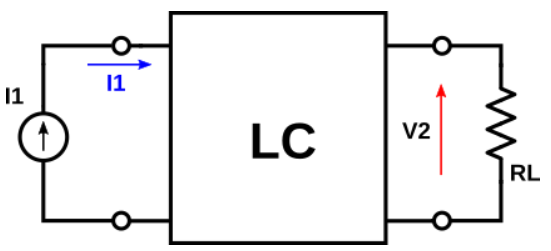

$$T(s) = \frac{V_2}{I_1} = \frac{k(s^2+9)}{s^3+2s^2+2s+1}$$



##**Sintetizar, hallar el valor de k que cumple con la síntesis y el valor de los componentes hallados**

In [8]:
import sympy as sp
from IPython.display import display, Math

s = sp.symbols('s')
w_z2 = -9

Z22 = (2*s**2 + 1) / (s**3 + 2*s)
Y22 = 1 / Z22

C1_val = sp.cancel(Y22 / s).subs(s**2, w_z2)
print(f"Capacitor derivación en Puerto 2 (C1): {C1_val} F")

YA = sp.simplify(Y22 - s*C1_val)
ZA = sp.simplify(1/YA)

kz = sp.cancel(ZA * (s**2 + 9) / s).subs(s**2, w_z2)
C2_val = 1 / kz
L2_val = 1 / (C2_val * 9)
print(f"\nTanque Serie (L2 || C2): L2 = {L2_val} H, C2 = {C2_val} F")

Z_tank = (kz * s) / (s**2 + 9)
ZB = sp.simplify(ZA - Z_tank)

YB = sp.simplify(1/ZB)
C3_val = sp.cancel(YB / s)
print(f"\nCapacitor derivación en Puerto 1 (C3): {C3_val} F")

Capacitor derivación en Puerto 2 (C1): 7/17 F

Tanque Serie (L2 || C2): L2 = 289/243 H, C2 = 27/289 F

Capacitor derivación en Puerto 1 (C3): 27/17 F


Para hallar k, evaluo el comportamiento de la red a frecuencia cero (corriente continua, $s=0$).

In [17]:
import sympy as sp
from IPython.display import display, Math

s, k = sp.symbols('s k')
w_z2 = -9

T2_expr = k * (s**2 + 9) / (s**3 + 2*s**2 + 2*s + 1)
T2_0 = T2_expr.subs(s, 0)

eq_k = sp.Eq(T2_0, 1)
k_val = sp.solve(eq_k, k)[0]

print(f"k = {k_val}\n")

k = 1/9



##**Verificación**

In [21]:
import sympy as sp
from IPython.display import display, Math

RL = 1
V2_sim = 1
I_carga = V2_sim / RL

I_C1 = V2_sim * (s * C1_val)
I_tank = I_carga + I_C1
V1_sim = V2_sim + I_tank * Z_tank
I_C3 = V1_sim * (s * C3_val)
I1_sim = sp.simplify(I_tank + I_C3)

T2_sintetizada = sp.cancel(V2_sim / I1_sim)
display(Math('T_{sint} = ' + sp.latex(T2_sintetizada)))
print("\n")
T2_orig = sp.cancel(T2_expr.subs(k, k_val))
display(Math('T_{orig} = ' + sp.latex(T2_orig)))
print("\n")
if sp.simplify(T2_sintetizada - T2_orig) == 0:
    print("Reconstruye la función original")

<IPython.core.display.Math object>

<IPython.core.display.Math object>



Reconstruye la función original.


#**3) Para la siguiente transferencia de tension-corriente:**

$$T(s) = \frac{V_2}{I_b} = \frac{k \cdot s \cdot (s^2 + \frac{1}{16})}{s^3 + 2s^2 + 2s+ 1}$$

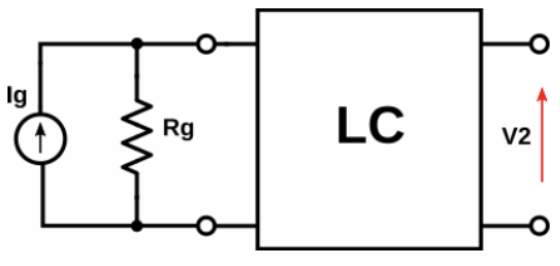

##**Sintetizar, hallar el valor de k para obtener -6dB en el centro de la banda de paso.**

La función es exactamente la misma que la del primer ejercicio. El generador de corriente $I_g$ con su resistencia $R_g$ pueden cambiarse por su equivalente de Thevenin; asumiendo $R_g=1$ entonces la fuente de tensión equivalente será $V=I_g \cdot R_g = I_g$  

Reemplazando por el equivalente de Thevenin, el circuito resulta exactamente el mismo que el de la primera consigna.
Mismo circuito y misma función, la síntesis será exactamente igual que el primer ejercicio.

$$20 \log_{10}(k) = -6\text{ dB}$$
$$k=0.501 ≈ \frac{1}{2}$$


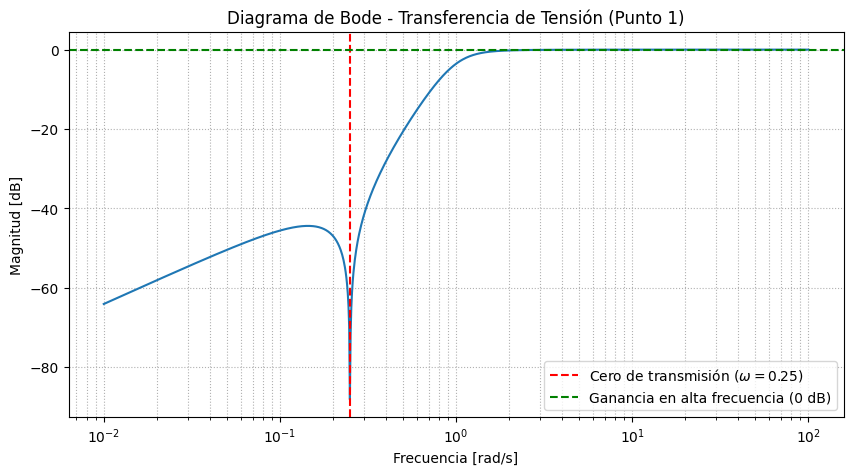

In [ ]:
import scipy.signal as signal
import matplotlib.pyplot as plt
import numpy as np

num = [1, 0, 1/16, 0]
den = [1, 2, 2, 1]

sys = signal.TransferFunction(num, den)

w = np.logspace(-2, 2, 1000)
w, mag, phase = signal.bode(sys, w)

plt.figure(figsize=(10, 5))
plt.semilogx(w, mag)
plt.title('Diagrama de Bode - Transferencia de Tensión (Punto 1)')
plt.xlabel('Frecuencia [rad/s]')
plt.ylabel('Magnitud [dB]')
plt.grid(which='both', axis='both', linestyle=':')
plt.axvline(0.25, color='red', linestyle='--', label=r'Cero de transmisión ($\omega = 0.25$)')
plt.axhline(0, color='green', linestyle='--', label='Ganancia en alta frecuencia (0 dB)')
plt.legend()
plt.show()

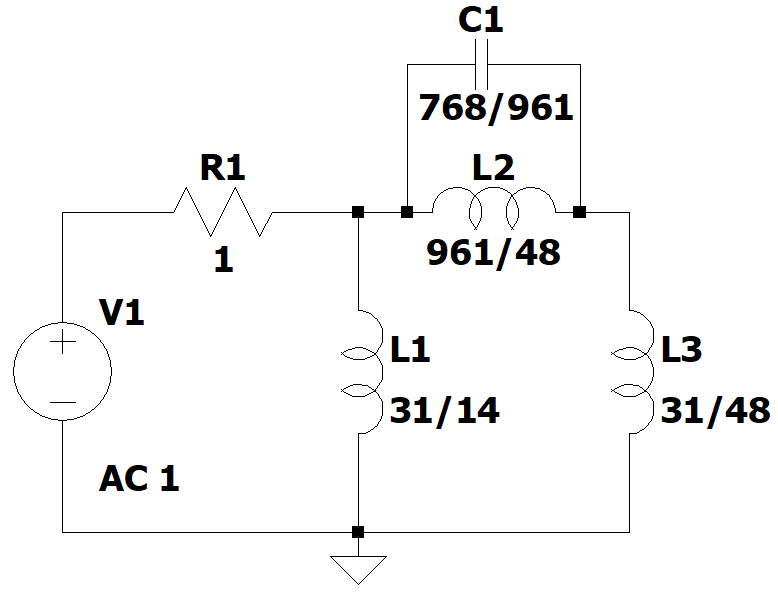

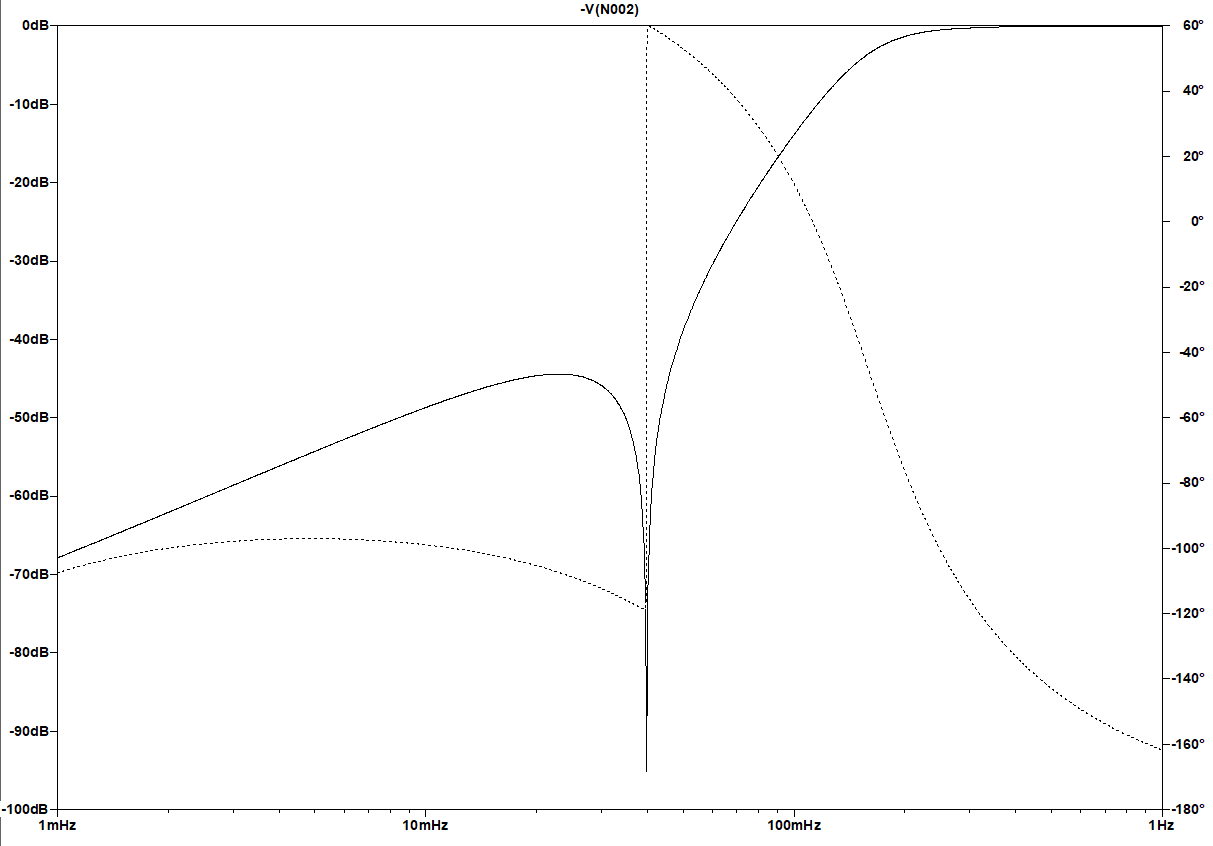

La simulación en LTspice y la de Python coinciden, verificando la función.